Exploratory Data Analysis (EDA) of the Cyberbullying Classification dataset obtained from Kaggle. The objective is to understand dataset characteristics, assess data quality, analyze class distributions and text properties, and prepare the data for downstream machine learning and deep learning models.

Link - https://www.kaggle.com/datasets/andrewmvd/cyberbullying-classification

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

file_path = "../data/raw/cyberbullying_tweets.csv"

df = pd.read_csv(file_path)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 47692 entries, 0 to 47691
Data columns (total 2 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   tweet_text          47692 non-null  str  
 1   cyberbullying_type  47692 non-null  str  
dtypes: str(2)
memory usage: 745.3 KB


In [2]:
df = df.rename(columns={"tweet_text": "tweet", "cyberbullying_type": "sentiment"})

Removing duplicate tweets to ensure each observation contributes only once during analysis and model training.

In [3]:
print(df[df.duplicated()].shape)
df = df[~df.duplicated()]

(36, 2)


Analyzing class distribution to identify potential class imbalance that may affect model training and evaluation.

sentiment
religion               7997
age                    7992
ethnicity              7959
gender                 7948
not_cyberbullying      7937
other_cyberbullying    7823
Name: count, dtype: int64


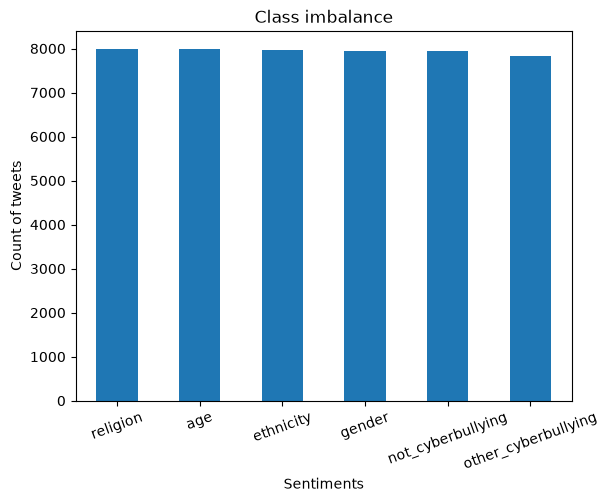

In [4]:
print(df.sentiment.value_counts())

plt.title('Class imbalance')
df['sentiment'].value_counts().plot.bar(rot = 20)
plt.xlabel('Sentiments')
plt.ylabel('Count of tweets')
plt.show()

In [5]:
!pip install emoji

Creating three separate preprocessing pipelines tailored to different model families -  TF-IDF based models, Word2Vec/GloVe + LSTM models, and Transformer based models. Classical machine learning models rely on normalized text representations and therefore benefit from more aggressive preprocessing, whereas sequence models and Transformers can leverage contextual information from raw text and require only minimal cleaning to preserve semantic information.

In [6]:
from __future__ import annotations

import re
import emoji

def clean_text_tfidf(text: str) -> str:
    """
    Preprocessing for TF-IDF based models
    """

    text = text.lower()

    # Expand common contractions
    contractions = {
        "can't": "can not",
        "won't": "will not",
        "n't": " not",
        "'re": " are",
        "'ve": " have",
        "'ll": " will",
        "'m": " am",
        "'d": " would",
        "'s": " is",
    }

    for old, new in contractions.items():
        text = text.replace(old, new)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Keep hashtag words (#hate -> hate)
    text = text.replace("#", "")

    # Remove emojis
    text = emoji.replace_emoji(text, replace="")

    # Remove punctuation
    text = re.sub(r"[^\w\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()

def clean_text_lstm(text: str) -> str:
    """
    Preprocessing for Word2Vec/GloVe/LSTM.
    """

    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Keep hashtag words (#hate -> hate)
    text = text.replace("#", "")

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()

def clean_text_transformer(text: str) -> str:
    """
    Minimal preprocessing for transformers.
    """
    
    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [7]:
df["clean_tfidf"] = df["tweet"].apply(clean_text_tfidf)
df["clean_lstm"] = df["tweet"].apply(clean_text_lstm)
df["clean_transformer"] = df["tweet"].apply(clean_text_transformer)

sample = df.sample(20)

for index, row in sample.iterrows():
    print(f"Original: {row['tweet']}")
    print(f"Cleaned (TF-IDF): {row['clean_tfidf']}")
    print(f"Cleaned (LSTM): {row['clean_lstm']}")
    print(f"Cleaned (Transformer): {row['clean_transformer']}")

Original: she said the n word twice, called someone retarded, and said Wyatt was gay as an insult and made rape jokes
Cleaned (TF-IDF): she said the n word twice called someone retarded and said wyatt was gay as an insult and made rape jokes
Cleaned (LSTM): she said the n word twice, called someone retarded, and said wyatt was gay as an insult and made rape jokes
Cleaned (Transformer): she said the n word twice, called someone retarded, and said Wyatt was gay as an insult and made rape jokes
Original: Yo fuck math. bunch of dumb niggers. and smellkanks. falln asleap on the bus
Cleaned (TF-IDF): yo fuck math bunch of dumb niggers and smellkanks falln asleap on the bus
Cleaned (LSTM): yo fuck math. bunch of dumb niggers. and smellkanks. falln asleap on the bus
Cleaned (Transformer): Yo fuck math. bunch of dumb niggers. and smellkanks. falln asleap on the bus
Original: @BarryGardiner I never realised how much of a brainless idiot you really are. You never said a word when Emily Jones was 

In [8]:
print("TF-IDF duplicates:", df["clean_tfidf"].duplicated().sum())
print("LSTM duplicates:", df["clean_lstm"].duplicated().sum())
print("Transformer duplicates:", df["clean_transformer"].duplicated().sum())

print("TF-IDF empty:", (df["clean_tfidf"] == "").sum())
print("LSTM empty:", (df["clean_lstm"] == "").sum())
print("Transformer empty:", (df["clean_transformer"] == "").sum())

TF-IDF duplicates: 2590
LSTM duplicates: 2316
Transformer duplicates: 1970
TF-IDF empty: 266
LSTM empty: 221
Transformer empty: 92


Analyzing tweet length distributions to understand the overall text characteristics of the dataset, identify potential outliers, and examine key percentile statistics. Also, comparing class-wise tweet lengths to determine whether certain cyberbullying categories exhibit distinct length patterns that may influence model performance.

In [9]:
df["tweet_length"] = (
    df["clean_tfidf"]
    .str.split()
    .str.len()
)

df["tweet_length"].describe()

count    47656.000000
mean        23.765024
std         16.082359
min          0.000000
25%         12.000000
50%         20.000000
75%         33.000000
max        755.000000
Name: tweet_length, dtype: float64

In [10]:
print(df.loc[
    df["tweet_length"].idxmax(),
    ["tweet", "clean_tfidf", "tweet_length"]
])

long_tweets = df[df["tweet_length"] > 300]
print("Number of long tweets:", len(long_tweets))

tweet           is feminazi an actual word with a denot…\r\n@N...
clean_tfidf     is feminazi an actual word with a denot my job...
tweet_length                                                  755
Name: 29205, dtype: object
Number of long tweets: 4


In [11]:
print(df["tweet_length"].quantile(
    [0.90, 0.95, 0.99, 0.995, 0.999]
))

print("Length 0:", (df["tweet_length"] == 0).sum())
print("Length 1:", (df["tweet_length"] == 1).sum())
print("Length 2:", (df["tweet_length"] == 2).sum())

0.900    48.0
0.950    52.0
0.990    57.0
0.995    59.0
0.999    62.0
Name: tweet_length, dtype: float64
Length 0: 266
Length 1: 490
Length 2: 486


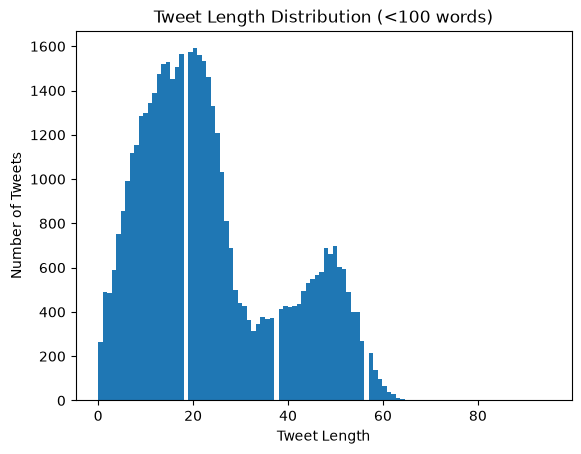

In [12]:
plt.hist(
    df[df["tweet_length"] < 100]["tweet_length"],
    bins=100
)

plt.xlabel("Tweet Length")
plt.ylabel("Number of Tweets")
plt.title("Tweet Length Distribution (<100 words)")

plt.show()

In [13]:
length_stats = (
    df.groupby("sentiment")["tweet_length"]
      .agg(
          count="count",
          mean="mean",
          median="median",
          std="std",
          min="min",
          max="max"
      )
      .round(2)
      .sort_values("mean", ascending=False)
)

print(length_stats)

                     count   mean  median    std  min  max
sentiment                                                 
religion              7997  33.81    37.0  14.24    1   95
age                   7992  33.09    32.0  15.36    2  276
ethnicity             7959  24.95    21.0  15.04    0  325
gender                7948  23.84    21.0  13.91    0  226
other_cyberbullying   7823  13.57    13.0  14.92    0  755
not_cyberbullying     7937  13.03    12.0   7.95    0  277


In [14]:
from collections import Counter

words = " ".join(df["clean_tfidf"]).split()

Counter(words).most_common(30)

[('the', 30960),
 ('i', 26077),
 ('a', 24890),
 ('to', 23540),
 ('and', 21720),
 ('is', 21500),
 ('you', 20630),
 ('of', 15384),
 ('in', 14984),
 ('not', 14571),
 ('that', 13127),
 ('it', 11942),
 ('are', 11113),
 ('school', 8855),
 ('for', 8707),
 ('me', 7775),
 ('my', 6841),
 ('was', 6802),
 ('this', 6758),
 ('they', 6486),
 ('but', 6467),
 ('on', 6219),
 ('do', 6187),
 ('have', 5980),
 ('like', 5910),
 ('fuck', 5884),
 ('who', 5670),
 ('all', 5643),
 ('be', 5513),
 ('with', 5462)]

In [15]:
for sentiment in sorted(df["sentiment"].unique()):

    text = " ".join(
        df.loc[df["sentiment"] == sentiment, "clean_tfidf"]
    )

    top_words = Counter(text.split()).most_common(20)

    print(f"\nTop 20 words for '{sentiment}'")
    print(top_words)


Top 20 words for 'age'
[('school', 8298), ('i', 8239), ('the', 7973), ('in', 6122), ('and', 6121), ('to', 6035), ('a', 5914), ('high', 5081), ('bullied', 4393), ('me', 3910), ('of', 3571), ('was', 3234), ('that', 3145), ('is', 3094), ('you', 2956), ('my', 2849), ('bully', 2756), ('it', 2596), ('who', 2505), ('for', 2429)]

Top 20 words for 'ethnicity'
[('the', 5544), ('fuck', 5223), ('dumb', 5213), ('you', 4830), ('nigger', 4465), ('a', 4089), ('i', 3954), ('to', 3329), ('is', 3266), ('and', 3149), ('ass', 2280), ('that', 2222), ('not', 2112), ('black', 2107), ('of', 2097), ('u', 1877), ('it', 1821), ('in', 1744), ('are', 1550), ('white', 1530)]

Top 20 words for 'gender'
[('a', 5375), ('rape', 4300), ('i', 4221), ('the', 4206), ('is', 4162), ('and', 3887), ('gay', 3877), ('not', 3515), ('jokes', 3455), ('to', 3307), ('you', 2642), ('it', 2259), ('of', 2183), ('that', 2096), ('are', 2072), ('joke', 1918), ('but', 1752), ('about', 1564), ('in', 1509), ('rt', 1253)]

Top 20 words for 'n

In [16]:
from pathlib import Path

df_tfidf = df[df["clean_tfidf"] != ""].copy()
df_lstm = df[df["clean_lstm"] != ""].copy()
df_transformer = df[df["clean_transformer"] != ""].copy()

processed_dir = Path("../data/processed")

df_tfidf.to_csv(
    processed_dir / "tweets_tfidf.csv",
    index=False
)

df_lstm.to_csv(
    processed_dir / "tweets_lstm.csv",
    index=False
)

df_transformer.to_csv(
    processed_dir / "tweets_transformer.csv",
    index=False
)